In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
print(f"Shape: {df.shape}, Head:\n{df.head()}, Data Types:\n{df.dtypes}")

Shape: (2443651, 9), Head:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  , Data Types:
uid                    int64
asin                  object
title  

In [3]:
# EDA Numerical vs Categoricals Columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns
print(f"Numerical Columns: {numerical_columns}")
print(f"Categorical Columns: {categorical_columns}")

Numerical Columns: Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')
Categorical Columns: Index(['asin', 'title', 'category'], dtype='object')


In [4]:
# EDA: Unique Data Types List
list(set(df.dtypes))

[dtype('O'), dtype('float64'), dtype('int64'), dtype('bool')]

In [5]:
# EDA: Uniques for numerical columns
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [6]:
# EDA: Separate between discrete and continuous variables
continuous = ['price', 'reviews', 'stars']
discrete = ['boughtInLastMonth']
print(f"Continuous: {continuous}")  
print(f"Discrete: {discrete}")

Continuous: ['price', 'reviews', 'stars']
Discrete: ['boughtInLastMonth']


In [7]:
# EDA: Check for missing values
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

1. Understanding Amazon product Categories

In [8]:
# Generate a frequency table for the product `category`.
df.category.value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [9]:
# Which are the top 5 most listed product categories?
df.category.value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

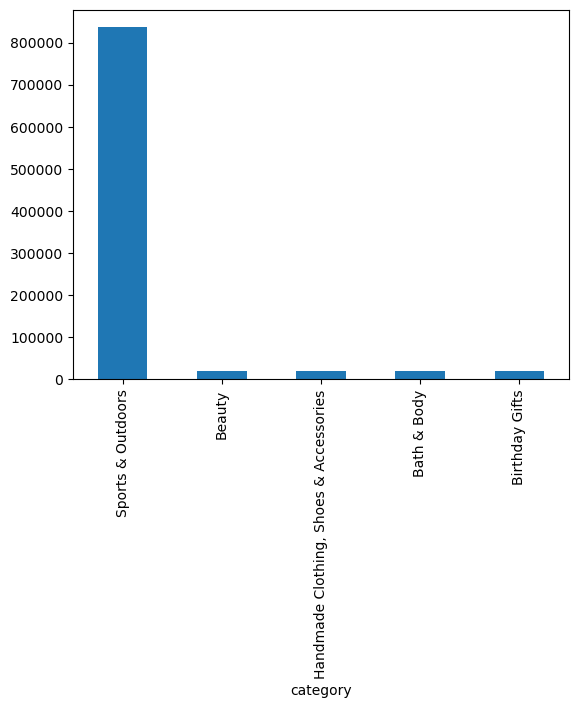

In [10]:
# Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
df.category.value_counts().head(5).plot.bar()
plt.show()  

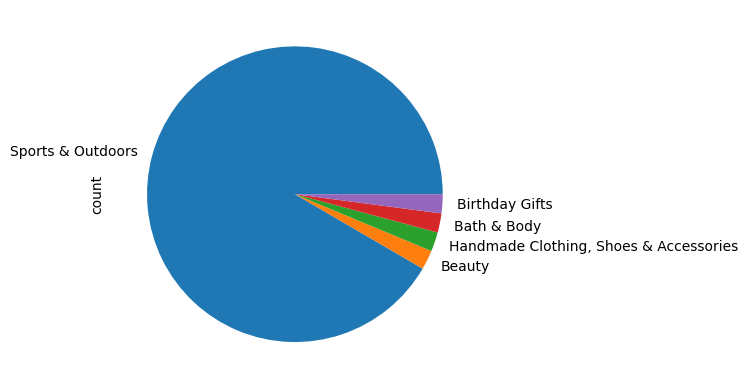

In [11]:
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
df.category.value_counts().head(5).plot.pie()
plt.show()

In [12]:
# Proportion table of the top 5 
df.category.value_counts(normalize=True)
# Sports & Outdoor dominate the listings by 34.22%

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
                                            ...   
Motorbike Chassis                         0.000044
Alexa Built-In Devices                    0.000044
Plugs                                     0.000044
Smart Home Security & Lighting            0.000043
Smart Speakers                            0.000022
Name: proportion, Length: 296, dtype: float64

2 Product Pricing

In [13]:
# Calculate the mean, median, and mode for the `price` of products
print(df.price.mean())
print(df.price.median())
print(df.price.mode())

89.24380943923663
19.09
0    9.99
Name: price, dtype: float64


In [14]:
# 89.24 is the average price point of products listed. The mode is 9.99 which is the most common price point.

In [15]:
# Determine the variance, standard deviation, range, and interquartile range for product `price`.
print(df.price.var())
print(df.price.std())
print(df.price.max() - df.price.min())
print(df.price.quantile(0.75) - df.price.quantile(0.25))

119445.48532256528
345.60886175352226
100000.0
36.0


In [16]:
# How varied are the product prices? Are there any indicators of a significant spread in prices?
# Ans. Yes, there are indicators of a significant spread in prices. The range is 99999.99, which is a large spread.
# The interquartile range is 36.00, which is also a large spread. The standard deviation is 345.60, which is also a large spread.

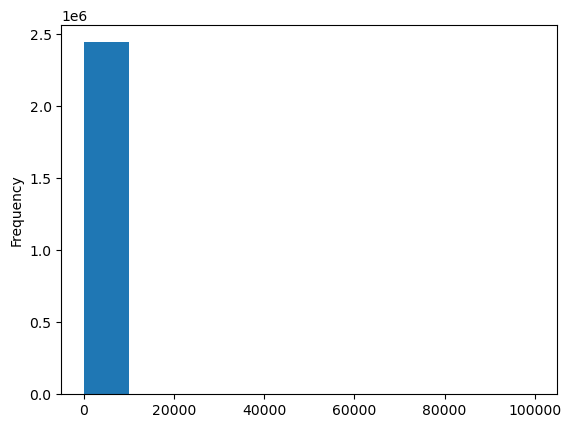

In [17]:
# Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.
df.price.plot.hist()
plt.show()

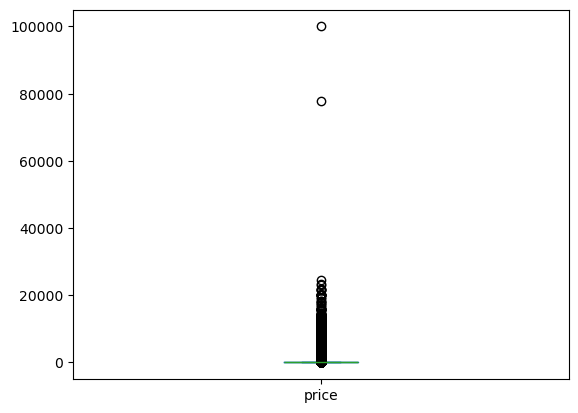

In [18]:
# Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 
df.price.plot.box()
plt.show()

3 Product Ratings

In [28]:
# Calculate the mean, median, and mode for the `rating` of products, not zero ratings.
print(df.stars.mean())
print(df.stars.median())
print(df.stars.mode())

2.152836472966065
0.0
0    0.0
Name: stars, dtype: float64


In [ ]:
# How do customers generally rate products? Is there a common trend?
# Ans. The average rating is 2.15

In [29]:
# Determine the variance, standard deviation, and interquartile range for product `rating`.
print(df.stars.var())
print(df.stars.std())
print(df.stars.quantile(0.75) - df.stars.quantile(0.25))

4.81743402976196
2.1948653785054697
4.4


In [ ]:
# Are the ratings consistent, or is there a wide variation in customer feedback?
# Ans. There is a wide variation in customer feedback.

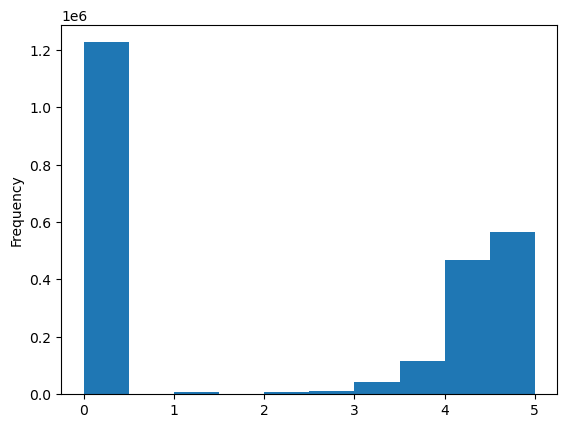

In [30]:
# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
df.stars.plot.hist()
plt.show()